<a href="https://colab.research.google.com/github/purinpurin11/Micas-blancas/blob/P-Caddick-%26-Thompson-(2008)-para-Mg-Si-en-fengita/Caddick_%26_Thompson_(2008)_para_Si_en_fengita_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
# ============================================================
# Cálculo de presiones con barómetro Si-en-fengita
# Fórmula corregida:
# P(GPa) = 8.35*Mg - 1.72*Si + 0.0015*T(K) + 4.59
#   Mg = Mg apfu de fengita
#   Si = Si apfu de fengita
#   T(K) = temperatura en Kelvin
# ============================================================

!pip install openpyxl -q

import pandas as pd
from google.colab import files

# 1. Subir archivo
print("Sube el archivo APFU_mica_blanca_11O.csv o .xlsx")
uploaded = files.upload()

archivo = list(uploaded.keys())[0]
print("Archivo cargado:", archivo)

# 2. Leer archivo
if archivo.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(archivo)
else:
    df = pd.read_csv(archivo)

# Limpiar nombres de columnas
df.columns = df.columns.str.strip()

# 3. Verificar columnas necesarias (Si y Mg)
for col in ["Si", "Mg"]:
    if col not in df.columns:
        raise ValueError(f"No se encontró la columna '{col}' en el archivo.")

# Verificar o crear columna Muestra
if "Muestra" not in df.columns:
    df = df.rename(columns={df.columns[0]: "Muestra"})

# 4. Temperaturas (en °C)
temperaturas = [
    ("468C", 468.0),
    ("519.75C", 519.75),
    ("571.5C", 571.5),
    ("623.25C", 623.25),
    ("675C", 675.0),
    ("768C", 768.0),
    ("783.5C", 783.5),
    ("799C", 799.0),
    ("814.5C", 814.5),
    ("830C", 830.0),
    ("870C", 870.0)
]

# 5. Calcular presiones con la nueva fórmula
# P(GPa) = 8.35*Mg - 1.72*Si + 0.0015*T(K) + 4.59
for nombre, T_C in temperaturas:
    T_K = T_C + 273.15
    df[f"P_GPa_{nombre}"] = (
        8.35 * df["Mg"]
        - 1.72 * df["Si"]
        + 0.0015 * T_K
        + 4.59
    )

# 6. Seleccionar únicamente las columnas solicitadas
columnas_salida = [
    "Muestra",
    "P_GPa_468C",
    "P_GPa_519.75C",
    "P_GPa_571.5C",
    "P_GPa_623.25C",
    "P_GPa_675C",
    "P_GPa_768C",
    "P_GPa_783.5C",
    "P_GPa_799C",
    "P_GPa_814.5C",
    "P_GPa_830C",
    "P_GPa_870C"
]

resultado = df[columnas_salida].copy()

# 7. Exportar a Excel con una sola hoja
nombre_salida = "Presiones_muestras.xlsx"

with pd.ExcelWriter(nombre_salida, engine="openpyxl") as writer:
    resultado.to_excel(
        writer,
        sheet_name="Presiones_muestras",
        index=False
    )

# 8. Mostrar resultado y descargar
display(resultado)

files.download(nombre_salida)

Sube el archivo APFU_mica_blanca_11O.csv o .xlsx


Saving APFU_mica_blanca_11O.xlsx to APFU_mica_blanca_11O (3).xlsx
Archivo cargado: APFU_mica_blanca_11O (3).xlsx


,Muestra,P_GPa_468C,P_GPa_519.75C,P_GPa_571.5C,P_GPa_623.25C,P_GPa_675C,P_GPa_768C,P_GPa_783.5C,P_GPa_799C,P_GPa_814.5C,P_GPa_830C,P_GPa_870C
0,25CA035-Z1-Wm-1,2.124915,2.202540,2.280165,2.357790,2.435415,2.574915,2.598165,2.621415,2.644665,2.667915,2.727915
1,25CA035-Z1-Wm-2,2.198939,2.276564,2.354189,2.431814,2.509439,2.648939,2.672189,2.695439,2.718689,2.741939,2.801939
2,25CA035-Z1-Wm-3,2.368375,2.446000,2.523625,2.601250,2.678875,2.818375,2.841625,2.864875,2.888125,2.911375,2.971375
3,25CA035-Z1-Wm-4,2.392875,2.470500,2.548125,2.625750,2.703375,2.842875,2.866125,2.889375,2.912625,2.935875,2.995875
4,25CA035-Z1-Wm-5,2.356057,2.433682,2.511307,2.588932,2.666557,2.806057,2.829307,2.852557,2.875807,2.899057,2.959057
5,25CA035-Z1-Wm-6,2.242098,2.319723,2.397348,2.474973,2.552598,2.692098,2.715348,2.738598,2.761848,2.785098,2.845098
6,25CA035-Z1-Wm-7,2.422720,2.500345,2.577970,2.655595,2.733220,2.872720,2.895970,2.919220,2.942470,2.965720,3.025720
7,25CA035-Z1-Wm-8,2.122907,2.200532,2.278157,2.355782,2.433407,2.572907,2.596157,2.619407,2.642657,2.665907,2.725907
8,25CA035-Z1-Wm-9,2.272654,2.350279,2.427904,2.505529,2.583154,2.722654,2.745904,2.769154,2.792404,2.815654,2.875654
9,25CA035-Z1-Wm-10,2.407092,2.484717,2.562342,2.639967,2.717592,2.857092,2.880342,2.903592,2.926842,2.950092,3.010092


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Sube el archivo Presiones_muestras.xlsx


Saving Presiones_muestras mg-si.xlsx to Presiones_muestras mg-si.xlsx
Archivo cargado: Presiones_muestras mg-si.xlsx
Temperaturas detectadas: [768.0, 783.5, 799.0, 814.5, 830.0, 870.0]
Columnas de presión: ['P_GPa_768C', 'P_GPa_783.5C', 'P_GPa_799C', 'P_GPa_814.5C', 'P_GPa_830C', 'P_GPa_870C']


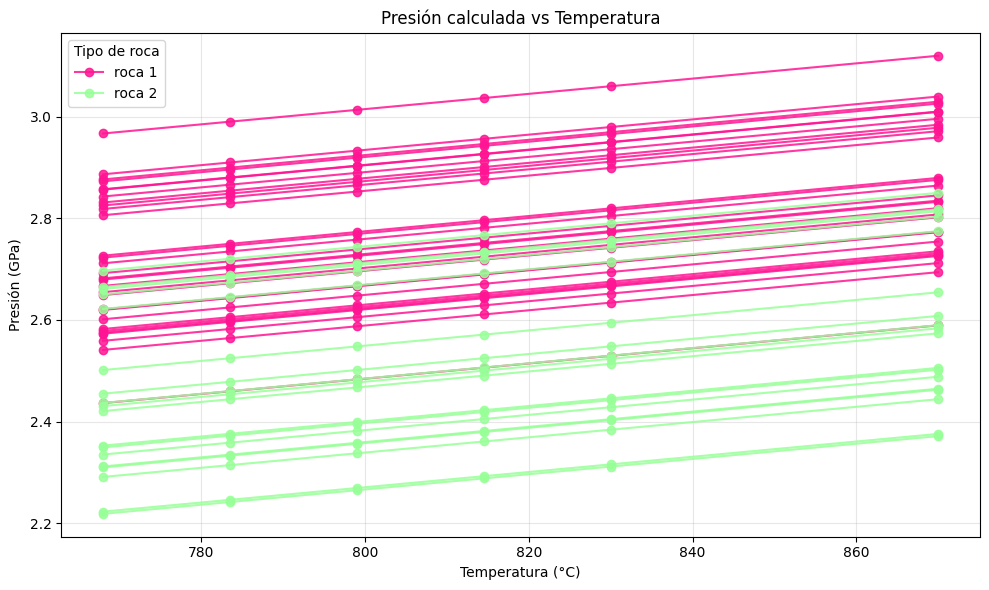

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# ============================================================
# Gráfico Temperatura vs Presión
# Colores por tipo de roca: roca 1 (rosa fuerte) y roca 2 (verde menta)
# ============================================================

!pip install openpyxl -q

import pandas as pd
import matplotlib.pyplot as plt
import re
from google.colab import files

# 1. Subir archivo Excel
print("Sube el archivo Presiones_muestras.xlsx")
uploaded = files.upload()

archivo = list(uploaded.keys())[0]
print("Archivo cargado:", archivo)

# 2. Leer hoja Presiones_muestras
df = pd.read_excel(archivo, sheet_name="Presiones_muestras")

# 3. Temperaturas que se quieren graficar
temperaturas_deseadas = [768, 783.5, 799, 814.5, 830, 870]

def extraer_temperatura(columna):
    """
    Extrae la temperatura desde el nombre de columna.
    Ejemplo: P_GPa_783.5C -> 783.5
    """
    match = re.search(r"P_GPa_([0-9.]+)C", str(columna))
    return float(match.group(1)) if match else None

# Detectar columnas de presión y quedarnos solo con las temperaturas deseadas
columnas_presion = [c for c in df.columns if str(c).startswith("P_GPa_")]

pares_temp_col = []
for c in columnas_presion:
    t = extraer_temperatura(c)
    if t is not None and any(abs(t - td) < 1e-6 for td in temperaturas_deseadas):
        pares_temp_col.append((t, c))

# Ordenar por temperatura
pares_temp_col = sorted(pares_temp_col, key=lambda x: x[0])

temperaturas = [p[0] for p in pares_temp_col]
columnas_P = [p[1] for p in pares_temp_col]

print("Temperaturas detectadas:", temperaturas)
print("Columnas de presión:", columnas_P)

# 4. Colores solicitados por tipo de roca
colores = {
    "roca 1": "#FF1493",  # rosa fuerte (DeepPink)
    "roca 2": "#98FF98",  # verde menta
    1: "#FF1493",         # Soporte por si viene como número entero
    2: "#98FF98"
}

# 5. Crear gráfico
plt.figure(figsize=(10, 6))

vistos = set()

# Determinar la columna de roca correcta en el archivo
columna_roca = "Roca" if "Roca" in df.columns else "Tipo de roca"

for _, fila in df.iterrows():
    roca = fila[columna_roca]

    # Convertir el valor a un formato de texto descriptivo para la leyenda
    if roca == 1 or str(roca).lower() == "roca 1":
        nombre_leyenda = "roca 1"
    elif roca == 2 or str(roca).lower() == "roca 2":
        nombre_leyenda = "roca 2"
    else:
        nombre_leyenda = str(roca)

    color = colores.get(roca, "gray")
    y = fila[columnas_P].astype(float).values

    # Para que la leyenda no repita el mismo tipo de roca
    etiqueta = nombre_leyenda if nombre_leyenda not in vistos else None

    plt.plot(
        temperaturas,
        y,
        marker="o",
        color=color,
        alpha=0.85,
        linewidth=1.5,
        markersize=6,
        label=etiqueta
    )

    vistos.add(nombre_leyenda)

plt.xlabel("Temperatura (°C)")
plt.ylabel("Presión (GPa)")
plt.title("Presión calculada vs Temperatura")
plt.grid(True, alpha=0.3)
plt.legend(title="Tipo de roca")
plt.tight_layout()

# 6. Guardar y descargar gráfico
nombre_png = "Grafico_Presiones_vs_Temperatura.png"
plt.savefig(nombre_png, dpi=300, bbox_inches="tight")
plt.show()

files.download(nombre_png)